# Inversión con función de onda compleja, sin potencial vectorial

**Qué hace.** Para $\psi=R\,e^{i\ell\theta}$ (forma de Fock–Darwin con $n=0$, $\ell=1$, $L=1$) calcula $V-E=\tfrac12\,\mathrm{Re}(\nabla^2\psi/\psi)$, con $\hbar=m=1$ y $\mathbf A=0$. Esto equivale a la ecuación de Madelung $V-E=\tfrac12\nabla^2R/R-\tfrac12|\nabla S|^2$, y la parte imaginaria es la continuidad. Valida con un corte en $y=0$.

**Revisado:**
- El signo es correcto: de $-\tfrac12\nabla^2\psi+V\psi=E\psi$ sale $V-E=\tfrac12\nabla^2\psi/\psi$. Comprobación puntual: recupera $\tfrac12r^2-2$ con error $\sim10^{-8}$, y la parte imaginaria es $\sim10^{-8}$.
- **Alcance:** con $L=1$ y $\mathbf A=0$, el estado es el del oscilador 2D sin campo ($\omega_c=0$). Sirve para el caso complejo con momento angular, pero no incluye el campo magnético.
- **Consecuencia importante:** aplicado a un estado de Fock–Darwin real ($\omega_0=1$, $\omega_c=2$), este mismo procedimiento sin $\mathbf A$ devuelve un confinamiento $\tfrac12\Omega^2 r^2$ con $\Omega^2=\omega_0^2+\omega_c^2/4=2$, el doble del verdadero $\tfrac12\omega_0^2 r^2$. Atribuye el confinamiento magnético al potencial escalar. Por eso hace falta el término $\nabla S-q\mathbf A$; la versión con campo está en `analisis/b1_validacion.py` (función `fock_darwin`).
- La energía se ajusta con el promedio de la diferencia en la región válida; puede compararse con el valor exacto $E=(2n+|\ell|+1)=2$ en estas unidades.
- La celda 0 usa $k=0.5$ solo para visualizar; la validación usa $k=1$.

**Pendiente:** comparar con $E$ exacta, reportar $|\mathrm{Im}|$ y añadir el caso con $\mathbf A\neq0$.

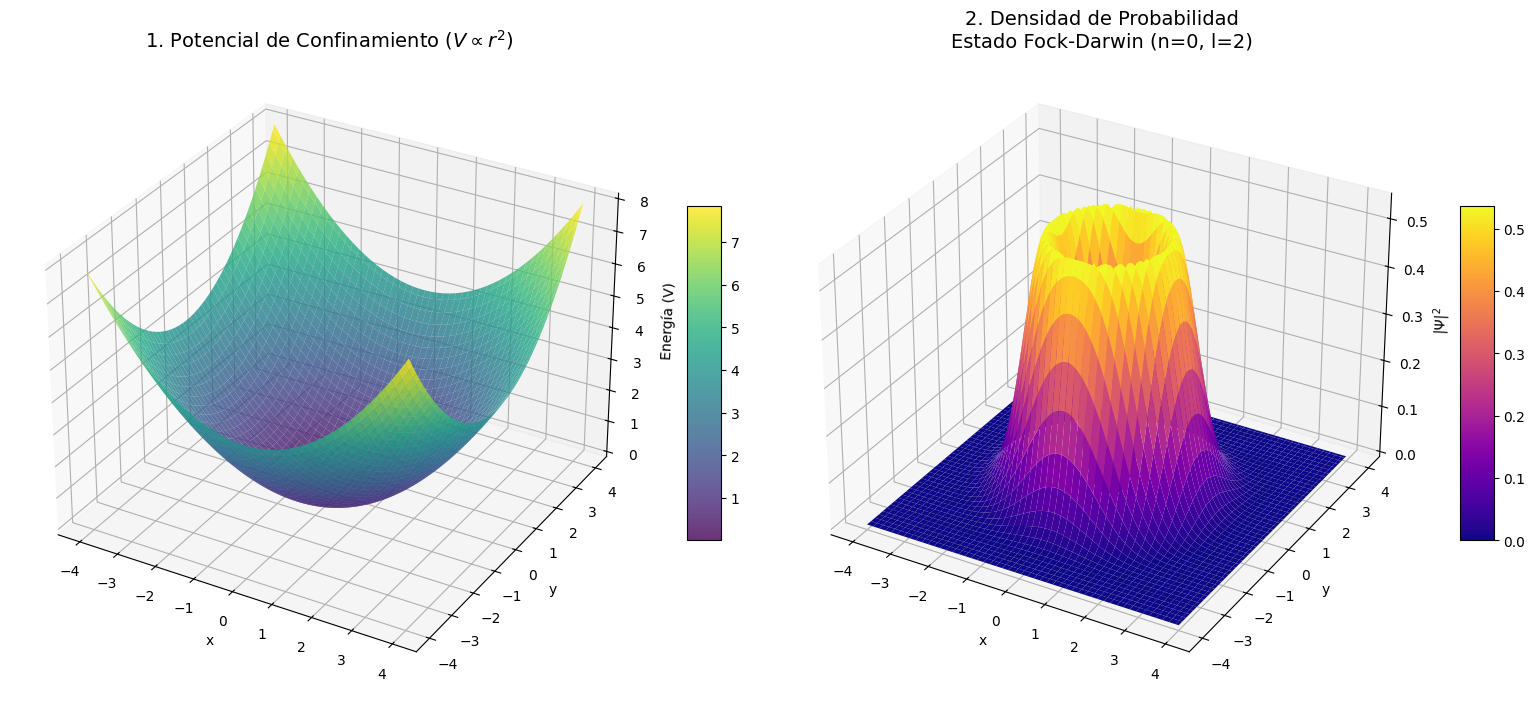

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from scipy.special import genlaguerre

# --- 1. Definición de Física ---

def harmonic_potential(r, k=1.0):
    """
    Potencial parabólico simple V ~ r^2
    k es una constante efectiva para visualización.
    """
    return 0.5 * k * r**2

def psi_fock_darwin(r, theta, n, l, L=1.0):
    """ Función de onda Fock-Darwin (igual que antes) """
    rho = (r**2) / (L**2)
    Laguerre_poly = genlaguerre(n, abs(l))(rho)
    R = (r**abs(l)) * Laguerre_poly * np.exp(-rho / 2.0)
    Y = np.exp(1j * l * theta)
    return R * Y

# --- 2. Configuración de Gráficos 3D ---

def plot_3d_comparison(n, l, L=1.0):
    # Crear malla (Grid)
    limit = 4.0 * L 
    points = 100
    x = np.linspace(-limit, limit, points)
    y = np.linspace(-limit, limit, points)
    X, Y = np.meshgrid(x, y)
    
    # Coordenadas polares para cálculo
    R = np.sqrt(X**2 + Y**2)
    Theta = np.arctan2(Y, X)
    
    # --- CÁLCULOS ---
    # A. El Potencial (Z1)
    # Usamos una k ajustada para que el gráfico no sea demasiado alto verticalmente
    Z_potencial = harmonic_potential(R, k=0.5) 
    
    # B. La Densidad de Probabilidad (Z2)
    psi = psi_fock_darwin(R, Theta, n, l, L)
    Z_prob = np.abs(psi)**2
    
    # --- GRAFICACIÓN ---
    fig = plt.figure(figsize=(16, 7))
    
    # Subplot 1: El Potencial
    ax1 = fig.add_subplot(1, 2, 1, projection='3d')
    surf1 = ax1.plot_surface(X, Y, Z_potencial, cmap='viridis', 
                             linewidth=0, antialiased=True, alpha=0.8)
    ax1.set_title("1. Potencial de Confinamiento ($V \propto r^2$)", fontsize=14)
    ax1.set_xlabel('x')
    ax1.set_ylabel('y')
    ax1.set_zlabel('Energía (V)')
    fig.colorbar(surf1, ax=ax1, shrink=0.5, aspect=10)

    # Subplot 2: La Densidad de Probabilidad
    ax2 = fig.add_subplot(1, 2, 2, projection='3d')
    surf2 = ax2.plot_surface(X, Y, Z_prob, cmap='plasma', 
                             linewidth=0, antialiased=True)
    ax2.set_title(f"2. Densidad de Probabilidad\nEstado Fock-Darwin (n={n}, l={l})", fontsize=14)
    ax2.set_xlabel('x')
    ax2.set_ylabel('y')
    ax2.set_zlabel('$|\Psi|^2$')
    fig.colorbar(surf2, ax=ax2, shrink=0.5, aspect=10)

    plt.tight_layout()
    plt.show()

# --- EJECUCIÓN ---
# Cambia estos valores para ver diferentes formas
n_input = 0  # Número radial (0, 1, 2...)
l_input = 2  # Momento angular (..., -1, 0, 1...)

plot_3d_comparison(n_input, l_input)

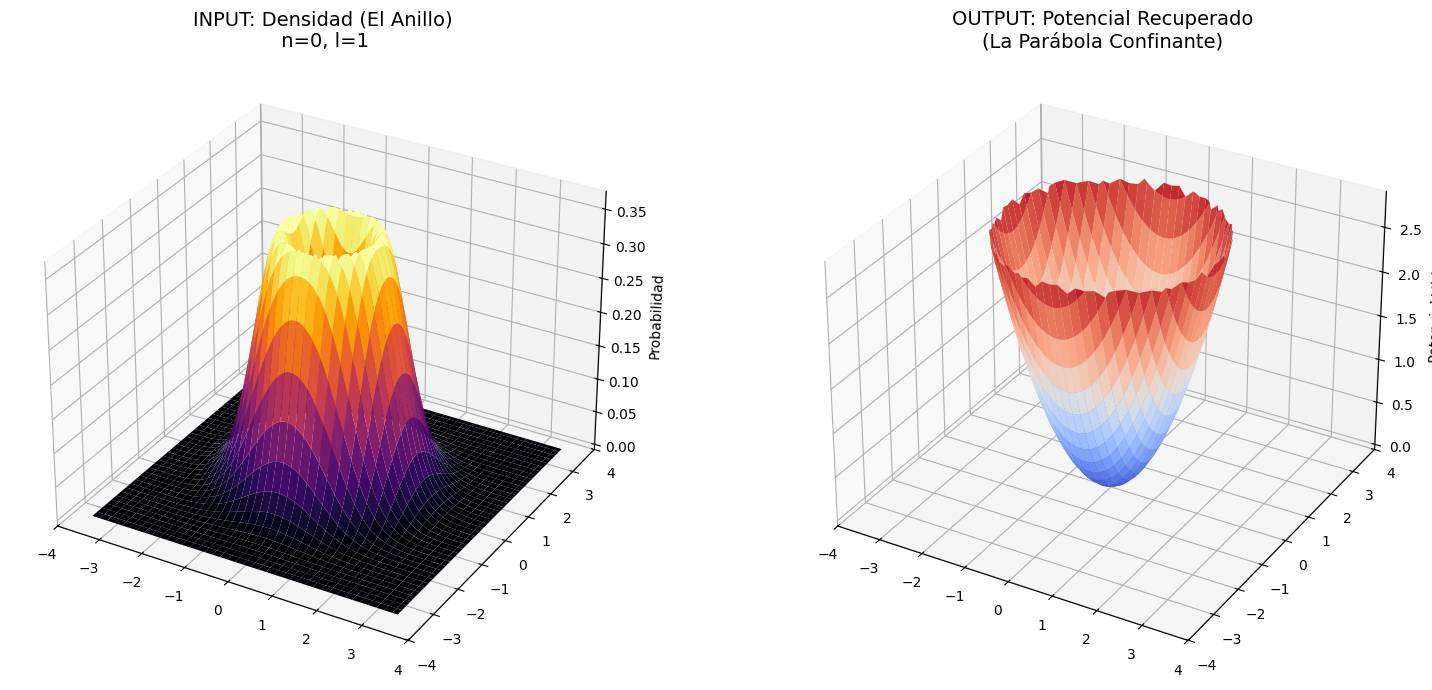

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import genlaguerre

# --- 1. GENERAR DATOS (Igual que antes) ---
def psi_fock_darwin(r, theta, n, l, L=1.0):
    rho = (r**2) / (L**2)
    Laguerre_poly = genlaguerre(n, abs(l))(rho)
    R = (r**abs(l)) * Laguerre_poly * np.exp(-rho / 2.0)
    Y = np.exp(1j * l * theta)
    return R * Y

def get_real_data(n, l, L=1.0):
    limit = 3.5 * L 
    points = 120
    x = np.linspace(-limit, limit, points)
    y = np.linspace(-limit, limit, points)
    X, Y = np.meshgrid(x, y)
    R = np.sqrt(X**2 + Y**2)
    Theta = np.arctan2(Y, X)
    Psi = psi_fock_darwin(R, Theta, n, l, L)
    return X, Y, Psi

# --- 2. MOTOR INVERSO CORREGIDO ---
def inverse_solver(Psi, X, Y):
    dx = X[0, 1] - X[0, 0]
    dy = Y[1, 0] - Y[0, 0]
    
    # Derivadas
    grad_x = np.gradient(Psi, dx, axis=1)
    grad_y = np.gradient(Psi, dy, axis=0)
    laplacian = np.gradient(grad_x, dx, axis=1) + np.gradient(grad_y, dy, axis=0)
    
    # Epsilon para estabilidad
    epsilon = 1e-15
    
    # FÓRMULA: V_raw = E + (1/2 * Laplaciano / Psi)
    # Aquí calculamos el término (V - E)
    # IMPORTANTE: Quitamos el signo menos manual que causó el error anterior
    # La ecuación de Schrödinger es (-1/2)Laplaciano + V = E
    # Entonces V = E + (1/2) * (Laplaciano / Psi)
    
    V_term = 0.5 * np.real(laplacian / (Psi + epsilon))
    
    # El resultado 'V_term' es en realidad V(r) - E.
    # Como V(r) es una parábola positiva (kr^2), V_term debería ser una parábola.
    return V_term

# --- 3. EJECUCIÓN ---

# Usaremos n=0, l=1 (El Anillo)
n_in = 0
l_in = 1 

# A. Datos
X, Y, Psi_exact = get_real_data(n_in, l_in)
Density = np.abs(Psi_exact)**2

# B. Inversión
V_raw = inverse_solver(Psi_exact, X, Y)

# C. Limpieza y Ajuste Visual
threshold = 0.05 * np.max(Density) # Umbral de limpieza
mask = Density > threshold

V_visual = np.ma.masked_where(~mask, V_raw)

# TRUCO VISUAL: 
# La matemática nos devuelve la forma correcta, pero desplazada verticalmente por la Energía E.
# Para que parezca un tazón que empieza en 0, le restamos el valor mínimo encontrado.
V_shifted = V_visual - np.min(V_visual)

# D. Gráficos
fig = plt.figure(figsize=(16, 7))

# Izquierda: Densidad
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf1 = ax1.plot_surface(X, Y, Density, cmap='inferno', linewidth=0, antialiased=True)
ax1.set_title(f"INPUT: Densidad (El Anillo)\n n={n_in}, l={l_in}", fontsize=14)
ax1.set_zlabel('Probabilidad')

# Derecha: Potencial
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
# Nota el cmap='coolwarm' para diferenciarlo visualmente
surf2 = ax2.plot_surface(X, Y, V_shifted, cmap='coolwarm', linewidth=0, antialiased=True)

ax2.set_title("OUTPUT: Potencial Recuperado\n(La Parábola Confinante)", fontsize=14)
ax2.set_zlabel('Potencial V(r)')

plt.tight_layout()
plt.show()

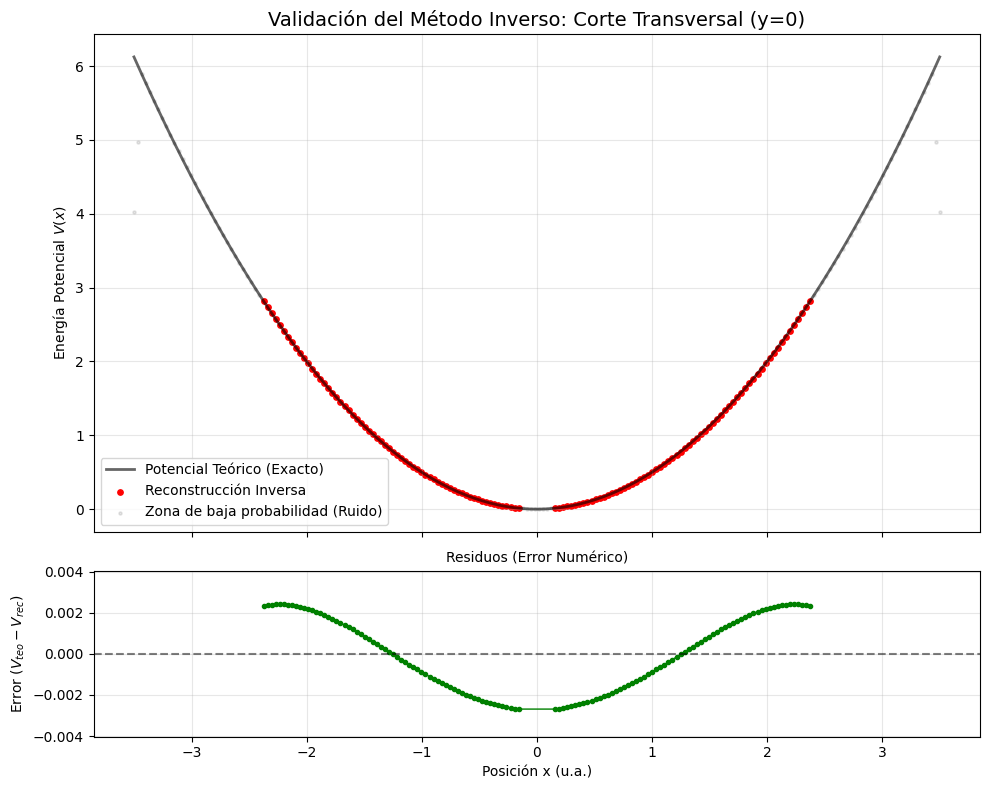

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import genlaguerre

# --- 1. DEFINICIONES FÍSICAS (Las mismas de siempre) ---
def psi_fock_darwin(r, theta, n, l, L=1.0):
    rho = (r**2) / (L**2)
    Laguerre_poly = genlaguerre(n, abs(l))(rho)
    R = (r**abs(l)) * Laguerre_poly * np.exp(-rho / 2.0)
    Y = np.exp(1j * l * theta)
    return R * Y

def theoretical_potential(r, k=1.0):
    # El potencial real que "escondimos" en la física
    # En unidades atómicas simplificadas para coincidir con la escala del problema
    return 0.5 * k * r**2 

# --- 2. GENERACIÓN Y RECONSTRUCCIÓN ---
L = 1.0
n_in = 0
l_in = 1  # Usamos el anillo de nuevo

# Grid
limit = 3.5 * L 
points = 200 # Más puntos para mayor precisión en el corte
x = np.linspace(-limit, limit, points)
y = np.linspace(-limit, limit, points)
X, Y = np.meshgrid(x, y)
R = np.sqrt(X**2 + Y**2)
Theta = np.arctan2(Y, X)

# Función de Onda y Densidad
Psi = psi_fock_darwin(R, Theta, n_in, l_in, L)
Density = np.abs(Psi)**2

# INVERSIÓN (Tu método)
dx = x[1] - x[0]
dy = y[1] - y[0]
grad_x = np.gradient(Psi, dx, axis=1)
grad_y = np.gradient(Psi, dy, axis=0)
laplacian = np.gradient(grad_x, dx, axis=1) + np.gradient(grad_y, dy, axis=0)

epsilon = 1e-15
# V_rec = E + (1/2 * Laplaciano / Psi)
# Nota: Aquí obtenemos V(r) - E_total
V_rec_2D = 0.5 * np.real(laplacian / (Psi + epsilon))


# --- 3. EL CORTE TRANSVERSAL (Slicing) ---

# Tomamos el índice de la mitad del array (donde y ~ 0)
mid_idx = points // 2

# Extraemos vectores 1D
r_slice = x  # El eje x actúa como radio (positivo y negativo)
V_rec_slice = V_rec_2D[mid_idx, :] # Corte del potencial recuperado
Density_slice = Density[mid_idx, :] # Corte de la densidad para referencia

# Potencial Teórico Exacto para comparar
# Nota: La constante k depende de las unidades. En este sistema adimensional
# donde L=1 y m=1, la parábola natural es 0.5 * r^2
V_theory_slice = 0.5 * r_slice**2

# --- 4. ALINEACIÓN DE ENERGÍA ---
# El método inverso recupera la FORMA, pero está desplazado verticalmente por la Energía E.
# V_recuperado = V_real - E
# Para compararlos, calculamos ese desplazamiento 'shift' usando solo los puntos válidos.

# Máscara: Solo confiamos donde hay densidad
mask = Density_slice > (0.05 * np.max(Density_slice))

# Calculamos el promedio de la diferencia en la región válida
energy_shift = np.mean(V_theory_slice[mask] - V_rec_slice[mask])

# Ajustamos nuestro resultado experimental
V_rec_adjusted = V_rec_slice + energy_shift


# --- 5. GRÁFICO DE VALIDACIÓN ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True, 
                               gridspec_kw={'height_ratios': [3, 1]})

# PANEL SUPERIOR: Comparación
# Graficamos la teoría (Línea sólida)
ax1.plot(r_slice, V_theory_slice, 'k-', lw=2, alpha=0.6, label='Potencial Teórico (Exacto)')

# Graficamos tu reconstrucción (Puntos) solo donde es válida
ax1.scatter(r_slice[mask], V_rec_adjusted[mask], color='red', s=15, label='Reconstrucción Inversa')

# (Opcional) Mostrar zonas muertas en gris suave
ax1.scatter(r_slice[~mask], V_rec_adjusted[~mask], color='gray', s=5, alpha=0.2, label='Zona de baja probabilidad (Ruido)')

ax1.set_ylabel('Energía Potencial $V(x)$')
ax1.set_title('Validación del Método Inverso: Corte Transversal (y=0)', fontsize=14)
ax1.legend()
ax1.grid(True, alpha=0.3)

# PANEL INFERIOR: El Error (Residuos)
# Error = Teoría - Reconstrucción
error = V_theory_slice[mask] - V_rec_adjusted[mask]

ax2.plot(r_slice[mask], error, 'g.-', lw=1)
ax2.axhline(0, color='k', linestyle='--', alpha=0.5)
ax2.set_ylabel('Error ($V_{teo} - V_{rec}$)')
ax2.set_xlabel('Posición x (u.a.)')
ax2.set_title('Residuos (Error Numérico)', fontsize=10)
ax2.grid(True, alpha=0.3)

# Ajustar límites Y del error para ver que es pequeño
max_err = np.max(np.abs(error)) if len(error) > 0 else 0.1
ax2.set_ylim(-max_err*1.5, max_err*1.5)

plt.tight_layout()
plt.show()